# MaxCut — ILP (PuLP)

$$\max \sum_{(i,j)\in E} y_{ij}
\quad s.t.\quad
y_{ij} \le x_i + x_j,\;
y_{ij} \le 2 - x_i - x_j,\;
x_i,y_{ij}\in\{0,1\}$$

Solver CBC vía PuLP. Baseline **clásico exacto**.


In [1]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

import pulp


In [2]:
def resolve_maxcut_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization" / "MaxCutOptimization"
        if root.is_dir():
            return root
    return Path.cwd().resolve() / "Notebooks" / "Optimization" / "MaxCutOptimization"


MAXCUT_DIR = resolve_maxcut_dir()
INSTANCE_PATH = MAXCUT_DIR / "instance" / "hamlib_maxcut.json"
METRICS_DIR = MAXCUT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

instance = json.loads(INSTANCE_PATH.read_text())
n = int(instance["n"])
edges = [tuple(e) for e in instance["edges"]]
OPTIMAL_CUT = int(instance["optimal_cut"])
OPTIMAL_BITS = list(instance["optimal_bits"])
nodes = list(range(n))

print(
    f"HamLib MaxCut | index={instance['hamlib_index']} id={instance['hamlib_id']} "
    f"n={n} |E|={len(edges)} optimal_cut={OPTIMAL_CUT}"
)
print("Fuente:", instance["url"])
print("Demo QAOA:", instance["demo_ref"])


def cut_value(bits) -> int:
    return int(sum(1 for a, b in edges if bits[a] != bits[b]))


def is_success(bits) -> bool:
    return cut_value(bits) == OPTIMAL_CUT


def save_maxcut_metrics(payload: dict, filename: str):
    path = METRICS_DIR / filename
    path.write_text(json.dumps(payload, indent=2))
    print("Saved:", path)
    return path


HamLib MaxCut | index=8 id=circ_offsets-1-2 n=6 |E|=12 optimal_cut=8
Fuente: https://pennylane.ai/datasets/hamlib-maxcut
Demo QAOA: https://pennylane.ai/demos/tutorial_qaoa_maxcut


## Modelo y resolución


In [3]:
def add_binary_dicts(prob, name, keys):
    """Compat PuLP 2.x / 4.x."""
    if hasattr(pulp, "LpVariable") and hasattr(pulp.LpVariable, "dicts"):
        return pulp.LpVariable.dicts(name, keys, cat="Binary")
    out = {}
    for k in keys:
        out[k] = pulp.LpVariable(f"{name}_{k}", cat="Binary")
        prob.addVariable(out[k])
    return out

def var_value(v):
    return float(pulp.value(v) or 0.0)

prob = pulp.LpProblem("maxcut", pulp.LpMaximize)
x = add_binary_dicts(prob, "x", list(range(n)))
y = {}
for i, j in edges:
    key = (i, j)
    if hasattr(pulp.LpVariable, "dicts"):
        # create one-by-one for edge keys
        pass
    y[key] = pulp.LpVariable(f"y_{i}_{j}", cat="Binary")
    if not hasattr(pulp.LpVariable, "dicts"):
        prob.addVariable(y[key])
    prob += y[key] <= x[i] + x[j]
    prob += y[key] <= 2 - x[i] - x[j]
prob += pulp.lpSum(y[e] for e in edges)

t0 = time.perf_counter()
prob.solve(pulp.PULP_CBC_CMD(msg=False))
elapsed = time.perf_counter() - t0
bits = [1 if var_value(x[i]) > 0.5 else 0 for i in range(n)]
c = cut_value(bits)
success = is_success(bits)
print("Status:", pulp.LpStatus[prob.status], "bits:", bits, "cut:", c)

payload = {
    "problem": "maxcut",
    "solver": "ilp",
    "family": "classical",
    "protocol": {
        "n_runs": 1,
        "method": "pulp_cbc_maxcut_ilp",
        "pulp_version": pulp.__version__,
        "sense": "maximize_cut",
        "hamlib_index": instance["hamlib_index"],
        "hamlib_id": instance["hamlib_id"],
    },
    "instance": {"n": n, "edges": [list(e) for e in edges], "source": instance["source"]},
    "quality": {
        "optimal_cost": float(OPTIMAL_CUT),
        "optimal_bits": OPTIMAL_BITS,
        "cost_mean": float(c),
        "cost_best": float(c),
        "gap_mean": float(OPTIMAL_CUT - c),
    },
    "success_rate": float(success),
    "time_s": {"mean": float(elapsed), "std": 0.0, "total": float(elapsed)},
    "effort": {},
    "runs": [{"seed": 0, "bits": bits, "cut": float(c), "success": bool(success), "time_s": float(elapsed)}],
}
save_maxcut_metrics(payload, "ilp_maxcut.json")


Status: Optimal bits: [0, 0, 1, 0, 1, 1] cut: 8
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/ilp_maxcut.json


PosixPath('/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/metrics/ilp_maxcut.json')

## Storytelling plots

Figuras para documento/slides → `figures/`.


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/instance_maxcut_graph.png


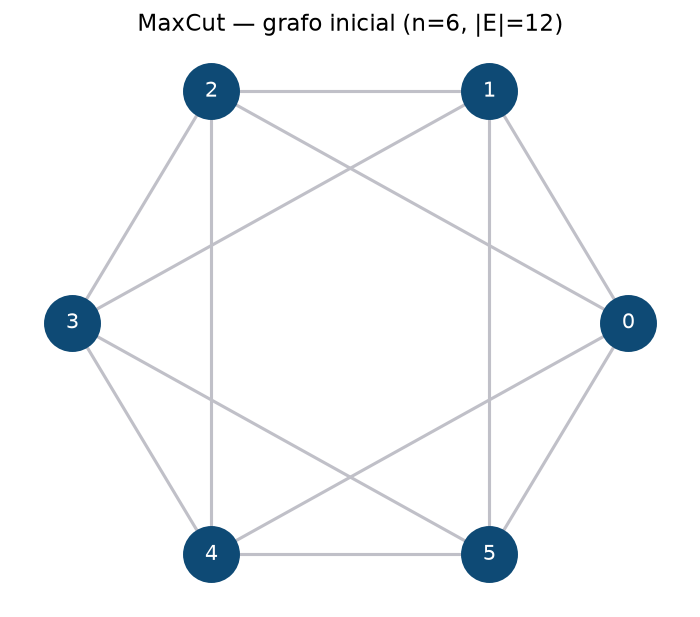

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/MaxCutOptimization/figures/ilp_maxcut_cut.png


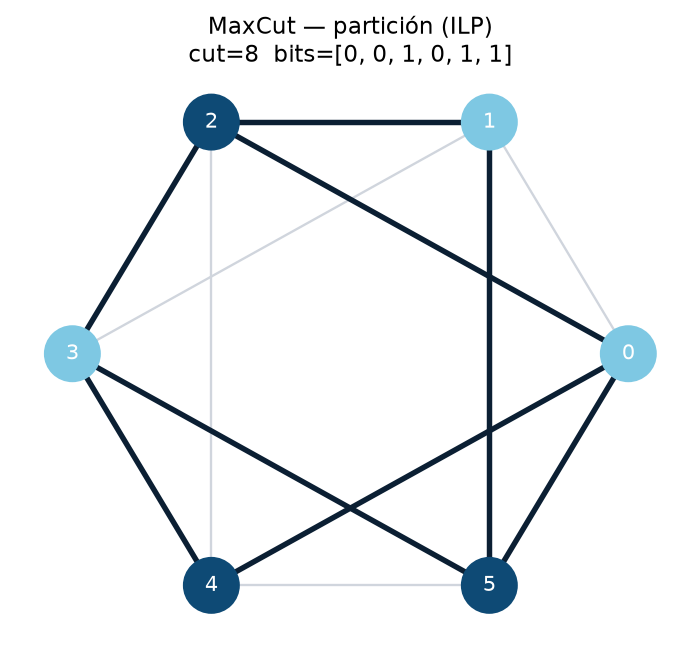

In [4]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import (
    resolve_figures_dir,
    plot_maxcut_instance, plot_maxcut_partition,
)

figures_dir = resolve_figures_dir("Optimization", "MaxCutOptimization")
plot_maxcut_instance(n, edges, figures_dir, stem="instance")
_bits = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("bits") is not None]
    if _runs:
        # MaxCut: higher cut is better
        _bits = max(_runs, key=lambda r: float(r.get("cut", r.get("cost", -1e18)))).get("bits")
if _bits is None and "best_b" in globals() and best_b is not None:
    _bits = best_b
if _bits is None and "bits" in globals() and isinstance(bits, (list, tuple)):
    _bits = bits
if _bits is None and "OPTIMAL_BITS" in globals():
    _bits = OPTIMAL_BITS
if _bits is None:
    raise RuntimeError("No MaxCut bits found for storytelling plot")
plot_maxcut_partition(n, edges, _bits, figures_dir, stem="ilp", title="ILP")

plt.show()
